# 5 · Assembling the transformer

**Question.** How does one attention calculation become a sequence model?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/05-transformers.ipynb)

Attention mixes information between positions. A transformer also transforms features within each position, preserves information through residual paths, and maps the resulting features to a prediction. We will build a small decoder-only model explicitly. The goal is to follow every tensor and verify the information boundary, not to reproduce the scale of a modern language model.

**Prerequisites:** Chapters 2–4. **Outcomes:** trace IDs to logits; distinguish normalization across features from normalization across a batch; implement a decoder block; test causality end to end. The entire example uses a CPU and randomly initialized parameters.

## Pipeline and framework

![Token embeddings plus positions pass through repeated pre-normalized causal attention and feed-forward residual blocks, then a final normalization and vocabulary head. Remember: attend, add, transform, add; then stack the blocks.](https://chikuang.github.io/teaching/genai/_static/diagrams/05-transformer.png)

The top lane expands one block; the bottom lane places that block inside the whole decoder. In our **pre-normalized** block, layer normalization precedes each learned sublayer. Two residual additions retain a direct path for the input states. Other normalization conventions exist, so identify the convention before comparing implementations.

| Boundary | Input and output | Check |
|:--|:--|:--|
| Embedding | IDs $(B,T)$ become states $(B,T,d)$. | Token and position indices remain inside their tables. |
| Attention sublayer | States $(B,T,d)$ become context-aware states of the same shape. | Head width divides model width; causal masking applies in every block. |
| Feed-forward sublayer | Each position expands to width $d_{ff}$ and returns to $d$. | Mixing across positions happens in attention, not in this positionwise MLP. |
| Vocabulary head | States become logits $(B,T,V)$. | Logits are unnormalized; the loss or sampler converts them as needed. |

**Training path:** input IDs for positions $1$ through $T$ predict target IDs for positions $2$ through $T+1$. **Generation path:** evaluate the current prefix, use the final-position logits, append a token, and repeat. The model architecture can be identical in both paths even though the surrounding computation differs. Whole-model future-leakage tests must cover positions, residual paths, and every attention layer.

## 5.1 · The route from IDs to probabilities

For a batch of $B$ sequences with $T$ input tokens, an embedding lookup produces $B\times T\times d$ features. We add position embeddings of the same width. A decoder block transforms those features without changing their shape. Finally, a linear head produces $B\times T\times V$ logits, one vector over the vocabulary at every position.

| Object | Shape | Interpretation |
|:--|:--|:--|
| Token IDs | $B\times T$ | Integer category labels |
| Hidden features | $B\times T\times d$ | Contextual vectors |
| Per-head scores | $B\times h\times T\times T$ | Query/key compatibility |
| Logits | $B\times T\times V$ | Unnormalized next-token scores |

The vocabulary axis is normalized only when probabilities are needed. Cross-entropy routines usually accept logits and perform the stable normalization internally.

## 5.2 · Residual paths and layer normalization

We use a pre-normalization block:

$$
U=X+\operatorname{Attention}(\operatorname{LN}(X)),\qquad
H=U+\operatorname{FFN}(\operatorname{LN}(U)).
$$

A residual connection adds an update to an existing representation. It also creates a direct path for gradients. Layer normalization standardizes each position's feature vector, then applies learned scale and shift parameters. It does not estimate a mean across the observations in the batch. In particular, it does not mix future positions into earlier ones.

The feed-forward network applies the **same** nonlinear function to each position independently, typically expanding the width and then projecting back. It introduces nonlinear feature interactions; attention is the component that communicates across positions. Pre-normalization is a teaching architecture choice and differs in detail from the post-normalization arrangement in the original transformer paper.

### Expand the two sublayers

For a single position's row vector $x\in\mathbb R^d$, layer normalization is

$$
\mu(x)=\frac1d\sum_{j=1}^d x_j,\quad
v(x)=\frac1d\sum_{j=1}^d(x_j-\mu(x))^2,\quad
\operatorname{LN}(x)_j=\gamma_j\frac{x_j-\mu(x)}{\sqrt{v(x)+\varepsilon}}+\beta_j.
$$

$\gamma,\beta\in\mathbb R^d$ are learned, and $\varepsilon>0$ stabilizes division. The variance uses denominator $d$, not $d-1$: this is a feature transformation, not an unbiased population-variance estimator. Each normalization layer has its own scale and shift. Batch and time axes remain separate.

With rows representing positions, our positionwise network is

$$
\operatorname{FFN}(X)=\operatorname{GELU}(XW_1+\mathbf1 b_1^\top)W_2
+\mathbf1 b_2^\top,
$$

where $W_1\in\mathbb R^{d\times d_{ff}}$, $W_2\in\mathbb R^{d_{ff}\times d}$, $b_1\in\mathbb R^{d_{ff}}$, $b_2\in\mathbb R^d$, and $d_{ff}=4d$ here. GELU acts on entries: $\operatorname{GELU}(u)=u\Phi(u)$, where $\Phi$ is the standard normal CDF. The two residual updates above both return an $n\times d$ matrix, so their additions are well-defined.

After the last block, the vocabulary head gives

$$
Z=\operatorname{LN}(H)W_{\mathrm{vocab}}+\mathbf1 b_{\mathrm{vocab}}^\top,
\qquad p_\theta(x_{t+1}=j\mid x_{\le t})=
\frac{e^{Z_{tj}}}{\sum_{v=1}^{V}e^{Z_{tv}}}.
$$

$W_{\mathrm{vocab}}\in\mathbb R^{d\times V}$ and $Z\in\mathbb R^{n\times V}$ for one sequence. The batch axis adds a leading dimension to every expression. `final_norm` and `head` implement this last equation; using the final-position row during generation is a selection of logits, not another learned layer.

## 5.3 · Implement a small decoder block

In [1]:
import math
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)
torch.manual_seed(5)

class DecoderBlock(nn.Module):
    def __init__(self, width=24, heads=3):
        super().__init__()
        assert width % heads == 0
        self.heads = heads
        self.head_width = width // heads
        self.norm1 = nn.LayerNorm(width)
        self.norm2 = nn.LayerNorm(width)
        self.qkv = nn.Linear(width, 3 * width)
        self.project = nn.Linear(width, width)
        self.ffn = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(),
                                 nn.Linear(4 * width, width))

    def forward(self, x):
        B, T, D = x.shape
        normalized = self.norm1(x)
        # Split feature coordinates, then expose a separate head axis.
        q, k, v = self.qkv(normalized).chunk(3, dim=-1)
        q, k, v = [a.reshape(B, T, self.heads, self.head_width)
                    .transpose(1, 2) for a in (q, k, v)]
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.head_width)
        allowed = torch.ones(T, T, dtype=torch.bool, device=x.device).tril()
        weights = torch.softmax(scores.masked_fill(~allowed, -torch.inf), dim=-1)
        mixed = (weights @ v).transpose(1, 2).contiguous().reshape(B, T, D)
        x = x + self.project(mixed)
        return x + self.ffn(self.norm2(x))

class TinyDecoder(nn.Module):
    def __init__(self, vocab_size=12, width=24, max_length=32):
        super().__init__()
        self.max_length = max_length
        self.token = nn.Embedding(vocab_size, width)
        self.position = nn.Embedding(max_length, width)
        self.block = DecoderBlock(width=width, heads=3)
        self.final_norm = nn.LayerNorm(width)
        self.head = nn.Linear(width, vocab_size)

    def forward(self, ids):
        T = ids.shape[1]
        if T > self.max_length:
            raise ValueError('Sequence exceeds the position table')
        positions = torch.arange(T, device=ids.device)
        x = self.token(ids) + self.position(positions)
        return self.head(self.final_norm(self.block(x)))

model = TinyDecoder()
ids = torch.tensor([[1, 2, 3, 4, 5], [4, 3, 2, 1, 0]])
logits = model(ids)
print('Input:', tuple(ids.shape), 'logits:', tuple(logits.shape))
print('Parameter count:', sum(p.numel() for p in model.parameters()))
assert logits.shape == (2, 5, 12)

Input: (2, 5) logits: (2, 5, 12)
Parameter count: 8628


`transpose` changes the view of tensor axes. Calling `contiguous()` before the final reshape makes the memory layout compatible with the requested merged head dimension. This is an implementation detail worth checking because reshaping the wrong axes can silently mix positions and heads.

There is no dropout in this teaching model. Production architectures often include additional regularization, more layers, different positional mechanisms, and optimized attention kernels. None of those additions changes the need to understand the basic information flow.

## 5.4 · Test the complete model for future leakage

In [2]:
model.eval()
changed = ids.clone()
changed[:, 3:] = torch.tensor([[8, 9], [10, 11]])
with torch.no_grad():
    original = model(ids)
    altered = model(changed)
    earlier_change = (original[:, :3] - altered[:, :3]).abs().max().item()
print('Maximum change at unchanged earlier positions:', earlier_change)
assert earlier_change < 1e-6

Maximum change at unchanged earlier positions: 0.0


The test covers embeddings, attention, normalization, the residual paths, and the output head together. It would fail if a layer pooled across all time positions and fed that pooled value back into earlier predictions. Always test the actual composed system, not only an isolated attention function.

## 5.5 · Shift the targets, not the information boundary

If a sequence is $(x_0,x_1,\ldots,x_T)$, the inputs are $(x_0,\ldots,x_{T-1})$ and targets are $(x_1,\ldots,x_T)$. The output at input position $t$ predicts the following token. Training can evaluate all these predictions in parallel because the causal mask prevents each one from seeing its target.

Initial and final training loss: 2.479 0.001


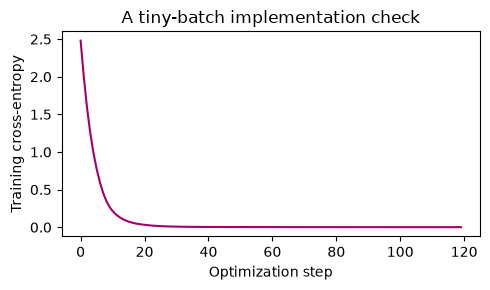

In [3]:
sequences = torch.tensor([[1, 2, 3, 4, 5, 6],
                          [2, 3, 4, 5, 6, 7],
                          [3, 4, 5, 6, 7, 8],
                          [4, 5, 6, 7, 8, 9]])
inputs, targets = sequences[:, :-1], sequences[:, 1:]
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
losses = []
model.train()
for step in range(120):
    optimizer.zero_grad()
    prediction = model(inputs)
    loss = nn.functional.cross_entropy(prediction.reshape(-1, 12), targets.reshape(-1))
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
print('Initial and final training loss:', round(losses[0], 3), round(losses[-1], 3))
assert losses[-1] < losses[0]
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(losses, color='#a2006e')
ax.set(xlabel='Optimization step', ylabel='Training cross-entropy',
       title='A tiny-batch implementation check')
plt.tight_layout()
plt.show()

This experiment intentionally overfits four short sequences. It establishes that gradients and targets are connected well enough to reduce this training objective. It does **not** establish language understanding or held-out performance. Chapter 6 introduces a separate validation and test protocol.

## 5.6 · Encoder, decoder, and encoder–decoder

An encoder can use bidirectional self-attention over the observed input; it is useful when the full input is available for representation or prediction. A decoder uses causal self-attention to support autoregressive generation. An encoder–decoder system first represents an input sequence, then generates an output sequence using causal self-attention and cross-attention to the encoder's representations.

A decoder-only language model can also condition on a prompt by placing the prompt before the generated continuation. The architectural label does not determine whether the system is helpful, truthful, or calibrated. Those are properties to investigate with task-specific evaluation.

## 5.7 · Scaling and computational constraints

The dense attention score matrix stores $B h T^2$ numbers. Doubling sequence length quadruples that matrix's size, before considering the other activations. The feed-forward layers also incur substantial computation, proportional to sequence length and the squared hidden width in this implementation.

During autoregressive inference, earlier keys and values can be cached rather than recomputed. Our model does not implement that optimization. Truncating a long prompt to fit a context window changes the conditioning information, and learned absolute position tables do not automatically support unseen positions. Computational shortcuts must be evaluated for their effect on the task.

## 5.8 · Exercises and worked solutions

1. **Target alignment:** for input `[2, 5, 1]` from sequence `[2, 5, 1, 7]`, what are the targets? **Solution:** `[5, 1, 7]`. Predicting `[2, 5, 1]` would train reconstruction of visible tokens rather than next-token prediction.
2. **Layer normalization:** can normalizing jointly across all time positions break causality? **Solution:** yes. A statistic computed from future positions can influence earlier representations even when attention itself is masked. Our `LayerNorm(width)` uses only the final feature axis.
3. **Head width:** what happens if width 25 is divided into 3 equal heads? **Solution:** the split is undefined; the constructor rejects it. Choose a compatible width or a projection design with explicitly different head dimensions.
4. **Memory:** how many score entries are needed for $B=2,h=4,T=128$? **Solution:** $2\cdot4\cdot128^2=131,072$. At four bytes each this array alone occupies 512 KiB. Training needs additional activations and gradients.
5. **Ablation:** remove position embeddings and fit the same tiny dataset. What can be concluded? **Solution:** only how that change affects this specific task and training budget. The causal mask already supplies an asymmetry, and the simple arithmetic sequences may not require rich position representations. Use a task designed to test order dependence before claiming positions are unnecessary.

## 5.9 · Reading and next step

Compare the components with the original [transformer paper](https://arxiv.org/abs/1706.03762), paying attention to encoder–decoder structure rather than assuming every transformer is decoder-only. Next, [Chapter 6](https://chikuang.github.io/teaching/genai/chapters/06-language-models.html) separates fitting a language distribution from choosing how to sample its outputs.